In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df_train = pd.read_csv('/kaggle/input/competitions/GiveMeSomeCredit/cs-training.csv')

In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [5]:
df_train.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [6]:
df_train = df_train.drop('Unnamed: 0', axis=1)

In [7]:
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix

In [70]:
X_train = df_train.drop('SeriousDlqin2yrs', axis=1)
y_train = df_train['SeriousDlqin2yrs']

In [71]:
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [73]:
model = XGBClassifier(
    random_state=42,
    learning_rate = 0.05,
    n_estimators = 200,
    n_jobs = -1
)

In [74]:
params = {'gamma' : [0.1, 0.3, 0.8]}

In [75]:
final_model = GridSearchCV(model, params, cv=3, scoring = 'roc_auc', verbose=1)

In [76]:
final_model.fit(X_train, y_train)

Fitting 3 folds for each of 3 candidates, totalling 9 fits


GridSearchCV(cv=3,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=0.05, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=200,
                                     n_jobs=-1, num_parallel_tree=None, ...),
             param_grid={'gamma': [0.1, 0.3, 0.8]}, scoring='roc_auc',
             verbose=1)

In [96]:
best_model = final_model.best_estimator_

In [97]:
y_pred = best_model.predict_proba(X_val)[:,1]

In [98]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)
youden = np.argmax(tpr - fpr)
best_threshold = thresholds[youden]

In [99]:
y_pred_bynary= (y_pred >= best_threshold).astype(int)

In [100]:
roc_auc_score(y_val, y_pred)

np.float64(0.8640892496133012)

In [101]:
confusion_matrix(y_val, y_pred_bynary)

array([[22186,  5858],
       [  424,  1532]])

In [102]:
print(classification_report(y_val, y_pred_bynary))

              precision    recall  f1-score   support

           0       0.98      0.79      0.88     28044
           1       0.21      0.78      0.33      1956

    accuracy                           0.79     30000
   macro avg       0.59      0.79      0.60     30000
weighted avg       0.93      0.79      0.84     30000



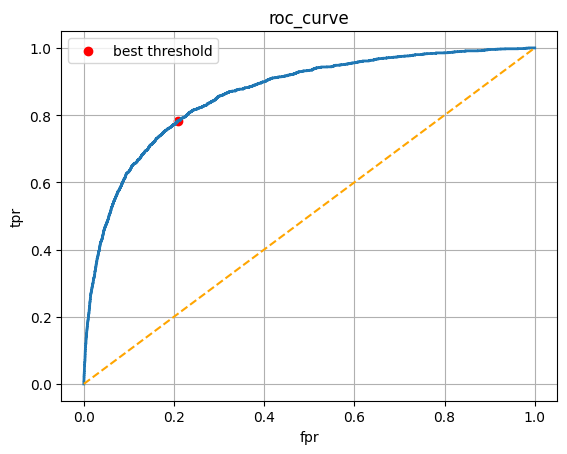

In [103]:
plt.plot(fpr, tpr, linewidth=2)
plt.plot([0,1],[0,1], color='orange', linestyle='dashed')
plt.scatter(fpr[youden], tpr[youden], color = 'red', label = 'best threshold')
plt.grid(True)
plt.xlabel('fpr')
plt.ylabel('tpr')
plt.title('roc_curve')
plt.legend()

In [111]:
best_model.save_model('final_model.json')